# 12 — PPO, DPO, GRPO and ORPO comparison

## Learning objectives

- Compare supervision, extra model roles and objectives.
- Plot analytical loss/clipping/normalization behavior.
- Make conditional resource and algorithm choices.

This notebook runs a small CPU demonstration by default. Synthetic experiments are educational, not evidence of LLM alignment. Pretrained-model downloads and GPU training require explicit opt-in. All runtime outputs stay inside `RLHF_NOTEBOOKS/`.

**Source connection:** All PDF/notebook model-role/algorithm contrasts and corrected notes Chapter08; cost figures are explicit state-only assumptions.

[Learning order and setup](README.md).

In [1]:
from pathlib import Path
import os, sys, json, math, random, copy, re, subprocess, hashlib
# Find this collection when launched from the repository, module, or notebook directory.
candidates = [Path.cwd(), Path.cwd()/'RLHF_NOTEBOOKS', Path.cwd()/'13_rlhf_ppo_dpo_orpo/RLHF_NOTEBOOKS']
ROOT = next((p.resolve() for p in candidates if (p/'source_inspection.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter from RLHF_NOTEBOOKS, its parent, or the repository root.')
RUNTIME = ROOT/'runtime'; RUNTIME.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR'] = str(RUNTIME/'matplotlib')
os.environ['HF_HOME'] = str(RUNTIME/'huggingface')
os.environ['HF_DATASETS_CACHE'] = str(RUNTIME/'huggingface/datasets')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['WANDB_DISABLED'] = 'true'
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
random.seed(42); np.random.seed(42); torch.manual_seed(42)
torch.set_num_threads(1)
print('Python', sys.version.split()[0], 'PyTorch', torch.__version__, 'CUDA', torch.cuda.is_available())

Python 3.13.9 PyTorch 2.8.0+cpu CUDA False


## Component and supervision comparison
| Method | Data and computation | Reference | Learned RM | Critic |
|---|---|---|---|---|
| PPO classical RLHF | Fresh prompts/responses; reward; GAE and clipping | Usually | Classical pipeline, or replace with function | Usually |
| DPO | Offline chosen/rejected pairs; reference-adjusted sequence logp margin | Standard formulation | No explicit RM | No |
| GRPO original | Same-prompt response groups; relative rewards and clipped objective | Original KL formulation | Optional scorer | No learned critic |
| ORPO | Offline pairs; chosen NLL plus normalized-likelihood log odds | No | No | No |

PPO is a general optimizer and can use an environment reward without an RM. DPO `ref_model=None` can share the base reference with PEFT. GRPO variants can remove KL/reference when coefficient0; they are not all identical to original GRPO. No method guarantees better alignment from lower training loss.

$$
\mathcal L_{DPO}=\operatorname{softplus}(-\beta m),\quad m=(\ell_w-\ell_l)-(\ell_{ref,w}-\ell_{ref,l}),\quad
\mathcal L_{ORPO}=-\bar\ell_w+\lambda_{OR}\operatorname{softplus}(-\Delta_{OR}).
$$
$\ell$ summed completion logp, $\bar\ell$ mean logp, $m$ relative margin, $\Delta_{OR}$ log-odds difference, beta DPO scale and lambda ORPO component weight. These look like logistic losses but their inputs and regularization differ.

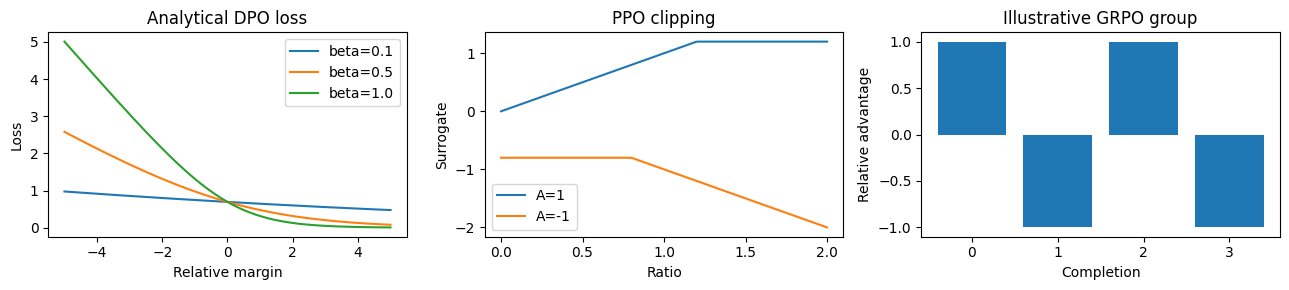

Illustrative GB (decimal), NOT measured VRAM: {'Single trainable model': 2.16, 'Policy + frozen reference': 2.7, 'PPO 2 trainable + 2 frozen': 5.4}


In [2]:
margin=np.linspace(-5,5,200);ratio=np.linspace(0,2,200)
fig,ax=plt.subplots(1,3,figsize=(13,3))
for beta in [.1,.5,1.]:ax[0].plot(margin,np.logaddexp(0,-beta*margin),label=f'beta={beta}')
ax[0].set(title='Analytical DPO loss',xlabel='Relative margin',ylabel='Loss');ax[0].legend()
ax[1].plot(ratio,np.minimum(ratio,np.clip(ratio,.8,1.2)),label='A=1');ax[1].plot(ratio,np.minimum(-ratio,-np.clip(ratio,.8,1.2)),label='A=-1');ax[1].set(title='PPO clipping',xlabel='Ratio',ylabel='Surrogate');ax[1].legend()
rewards=np.array([1.,0.,1.,0.]);adv=(rewards-rewards.mean())/rewards.std()
ax[2].bar(range(4),adv);ax[2].set(title='Illustrative GRPO group',xlabel='Completion',ylabel='Relative advantage');plt.tight_layout();plt.show()
# Model-state estimate only: assumptions FP32 weights+grads+Adam moments=16 bytes
# per trainable parameter, frozen FP32 copy=4. Excludes activations, buffers, caches.
P=135_000_000
estimates={'Single trainable model':16*P/1e9,'Policy + frozen reference':20*P/1e9,'PPO 2 trainable + 2 frozen':40*P/1e9}
print('Illustrative GB (decimal), NOT measured VRAM:',estimates)

## Selection workflow

Only offline preference pairs and a strong SFT checkpoint: start with DPO and validate the reference. Joint imitation/preference with no reference budget: consider ORPO. Verifiable reward plus generation capacity: GRPO is reasonable. Established reward model with broader online reward objective: PPO may be appropriate, with more engineering and critic overhead. Group generation cost scales with G and response length; memory scales with model states and activations, not just named roles. PEFT/reference caching/quantization can change rankings. The 20-row local dataset is educational and length-confounded; no universal winner can be concluded from it.

## Exercises

1. Estimate state memory for LoRA while retaining frozen base copies.
2. Design a fair evaluation suite rather than comparing incomparable training losses.
3. Choose a method for offline pairs versus a unit-test correctness reward.

## Key takeaways

Recompute the worked examples, inspect masks and gradients, and evaluate independently of the training objective. A small training-loss decrease does not establish generalization or alignment. Record the model, data split, seeds and dependency versions before interpreting results.